# 27 — Bank design, time-local whitening and PSD-estimation uncertainty

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extensions 40, 43 and 57 on the sine-Gaussian bank:

* **40. Bank design.** Fitting factor (fraction of the optimal SNR recovered, noiseless) and ρ₅₀ in real noise against the number of templates (20 → 640), for a regular grid and for a random ("stochastic") placement of the same number of templates.
* **43. Time-local whitening.** Each 512 s block of every chunk is whitened with a PSD estimated from the block and its two neighbours (≈1500 s) instead of the whole 4096 s chunk; effect on the epoch dependence of the FAP (leave-one-chunk-out spread) and on ρ₅₀.
* **57. PSD uncertainty.** In *synthetic Gaussian* noise with the PSD of a real chunk, the series is whitened with a median-Welch PSD estimated on only T = 32 … 4096 s of data; the observed FAP at the ideal threshold shows how the estimation noise of the PSD inflates the false alarms, and which T makes it negligible (the project uses 4096 s).

**What it does not do.** The "fitting factor" uses sine-Gaussian injections of the project prior, not a template-placement metric of the full parameter space; the time-local PSD removes slow non-stationarity but not glitches; the PSD-uncertainty study is Gaussian (no glitches), so it isolates the estimation noise.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import gwosc_tools as g
g.style()
rng = np.random.default_rng(27)
NCH = len(g.chunks()); CH = {i: g.load_chunk(i) for i in range(NCH)}
V, ID = {}, {}
for sp in ("train", "val", "test"): V[sp], ID[sp], _ = g.load_split(sp)
SNRS = [3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 16]; NINJ = 250

## 40. Bank design: number and placement of templates

In [2]:
def make_bank(S1, nf, nq, random=False, seed=0):
    f0s = np.geomspace(40, 450, nf); Qs = np.geomspace(3, 16, nq) if nq > 1 else np.array([8.0])
    b = g.SGBank(S1, f0s=f0s, Qs=Qs)
    if random:                      # same number of templates, random (f0 log-uniform, Q uniform)
        r = np.random.default_rng(seed); n = nf * nq; b = g.SGBank(S1, f0s=np.exp(r.uniform(np.log(40), np.log(450), n)), Qs=np.array([8.0]))
        Q = r.uniform(3, 16, n); b.Q = Q; T = 2.0 * g.sine_gaussian_ft(g.FREQ[None, :], b.f0[:, None], Q[:, None], 0.0, positive_only=True) / np.sqrt(S1)[None, :] * g.BAND
        b.norm2 = np.sum(np.abs(T) ** 2, axis=1); b.T = (T / np.sqrt(b.norm2)[:, None]).astype(np.complex64); b.grid = list(zip(b.f0, Q))
    return b
DESIGNS = [("regular 5x4 = 20", 5, 4, False), ("regular 10x4 = 40", 10, 4, False), ("regular 20x4 = 80", 20, 4, False), ("regular 40x4 = 160 (project)", 40, 4, False), ("regular 80x8 = 640", 80, 8, False),
           ("random 40", 10, 4, True), ("random 160", 40, 4, True)]
S1ref = CH[3]["S1"]; vte = V["test"]; cte = ID["test"]
sg_inj = g.inject(np.zeros((600, g.NWIN), np.float32), "sg", 10.0, rng, S1ref)[0]
FF = {}
for name, nf, nq, rnd in DESIGNS:
    b = make_bank(S1ref, nf, nq, rnd); FF[name] = float(np.mean(np.sqrt(b.scan(g.to_bins(sg_inj))["rho2"]) / 10.0)); print(f"{name}: fitting factor {FF[name]:.3f}, templates {len(b.grid)}")

regular 5x4 = 20: fitting factor 0.779, templates 20


regular 10x4 = 40: fitting factor 0.907, templates 40


regular 20x4 = 80: fitting factor 0.966, templates 80


regular 40x4 = 160 (project): fitting factor 0.985, templates 160


regular 80x8 = 640: fitting factor 0.996, templates 640
random 40: fitting factor 0.937, templates 40


random 160: fitting factor 0.984, templates 160


In [3]:
# rho50 in real noise (validation noise subset for the threshold, test injections), single PSD of chunk 3 -> use per-window banks via scan_mixed with a bank per chunk
fn = os.path.join(g.CACHE, "stats27_bank.pkl")
if os.path.exists(fn): RES = pickle.load(open(fn, "rb"))
else:
    RES = {}; vva, cva = V["val"], ID["val"]; sel = np.random.default_rng(1).choice(len(vva), 6000, replace=False); r = np.random.default_rng(2)
    INJ = {(k, s): None for k in g.MORPHS for s in SNRS}
    for k in g.MORPHS:
        for s in SNRS:
            i = r.choice(len(vte), NINJ, replace=False); INJ[(k, s)] = (g.inject(vte[i], k, float(s), r, np.stack([CH[c]["S1"] for c in cte[i]]))[0], cte[i])
    for name, nf, nq, rnd in DESIGNS:
        t0_ = time.time(); banks = {c: make_bank(CH[c]["S1"], nf, nq, rnd) for c in CH}; bg = g.scan_mixed(vva[sel], cva[sel], banks)["rho2"]
        sc = {key: g.scan_mixed(x, c, banks)["rho2"] for key, (x, c) in INJ.items()}; out = {}
        for far in (1e-2, 1e-3):
            rr = [g.bootstrap_rho(bg, [sc[(k, s)] for s in SNRS], SNRS, far, B=150, seed=4) for k in g.MORPHS]
            out[far] = (float(np.mean([np.nan_to_num(p[0], nan=16) for p, _ in rr])), float(np.sqrt(sum(((g.ci(b[:, 0])[1] - g.ci(b[:, 0])[0]) / 2) ** 2 for _, b in rr)) / 3))
        RES[name] = out; print(name, {k: tuple(round(x, 2) for x in v) for k, v in out.items()}, "%.0f s" % (time.time() - t0_), flush=True)
    pickle.dump(RES, open(fn, "wb"))
BD = pd.DataFrame([dict(design=k, n_templates=len(make_bank(S1ref, nf, nq, rnd).grid), fitting_factor=FF[k], rho50_1e2=RES[k][1e-2][0], err_1e2=RES[k][1e-2][1], rho50_1e3=RES[k][1e-3][0], err_1e3=RES[k][1e-3][1]) for k, nf, nq, rnd in DESIGNS]).set_index("design"); BD.round(3)

,n_templates,fitting_factor,rho50_1e2,err_1e2,rho50_1e3,err_1e3
design,,,,,,
regular 5x4 = 20,20,0.779,6.237,0.079,10.155,0.959
regular 10x4 = 40,40,0.907,5.802,0.067,8.354,0.466
regular 20x4 = 80,80,0.966,5.609,0.060,8.219,0.571
regular 40x4 = 160 (project),160,0.985,5.574,0.060,8.402,0.622
regular 80x8 = 640,640,0.996,5.570,0.053,8.480,0.594
random 40,40,0.937,5.755,0.057,8.673,0.799
random 160,160,0.984,5.621,0.060,7.996,0.591


## 43. Time-local whitening (blocks of 512 s, PSD from ±1 block)

In [4]:
BLK = 512; MARG = 16; FSR = g.FS_RAW
def whiten_local(i):
    meta = g.chunks()[i]; x = np.load(os.path.join(g.CACHE, "raw", meta["file"])).astype(np.float64); n = len(x); vs, S1s = [], []
    for b in range(n // (BLK * FSR)):
        a0, a1 = b * BLK * FSR, (b + 1) * BLK * FSR; seg = x[max(0, a0 - MARG * FSR): min(n, a1 + MARG * FSR)]
        psd = g.welch_psd(x[max(0, a0 - BLK * FSR): min(n, a1 + BLK * FSR)]); v, f, S = g.whiten_chunk(seg, psd=psd)
        lo = (MARG if a0 > 0 else 0) * g.FS; v = v[lo: lo + BLK * g.FS]; vs.append(v); S1s.append(g.psd_1hz(f, S))
    return np.concatenate(vs), S1s
fn = os.path.join(g.CACHE, "local_windows27.npz")
if os.path.exists(fn):
    z = np.load(fn); LW = {i: dict(v=z[f"v{i}"], blk=z[f"b{i}"], S1b=z[f"s{i}"]) for i in range(NCH)}
else:
    LW = {}
    for i in range(NCH):
        v, S1s = whiten_local(i); w = g.make_windows(v); first = g.TRIM * g.FS; blk = np.minimum(((first + np.arange(len(w)) * g.NWIN + g.NWIN // 2) // (BLK * g.FS)), len(S1s) - 1)
        LW[i] = dict(v=w, blk=blk.astype(int), S1b=np.array(S1s))
    np.savez_compressed(fn, **{f"{k}{i}": LW[i][n] for i in LW for k, n in (("v", "v"), ("b", "blk"), ("s", "S1b"))})
print({i: LW[i]["v"].shape for i in LW})

{0: (4056, 1024), 1: (4056, 1024), 2: (4056, 1024), 3: (4056, 1024), 4: (4056, 1024), 5: (4056, 1024), 6: (4056, 1024), 7: (4056, 1024)}


In [5]:
def bank_for(i, b): return g.SGBank(LW[i]["S1b"][b])
LB = {(i, b): bank_for(i, b) for i in LW for b in np.unique(LW[i]["blk"])}
fn = os.path.join(g.CACHE, "stats27_local.pkl")
if os.path.exists(fn): LOC = pickle.load(open(fn, "rb"))
else:
    LOC = {}
    for i in LW:
        cid = np.array([hash((i, b)) for b in LW[i]["blk"]]); keys = {hash((i, b)): LB[(i, b)] for b in np.unique(LW[i]["blk"])}
        LOC[i] = g.scan_mixed(LW[i]["v"], cid, keys)["rho2"]
    pickle.dump(LOC, open(fn, "wb"))
def cscan(n): d = np.load(os.path.join(g.CACHE, f"scan03_{n}.npz")); return d["rho2"]
GLO = {}
for sp in ("train", "val", "test"):
    r_ = cscan(sp)
    for c in np.unique(ID[sp]): GLO[c] = r_[ID[sp] == c]
rows = []
for lab, D in (("global PSD (chunk)", GLO), ("local PSD (blocks of 512 s)", LOC)):
    for far in (1e-2, 1e-3):
        ratios = [float((D[c] > g.threshold_at_far(np.concatenate([D[k] for k in D if k != c]), far)).mean() / far) for c in sorted(D)]
        rows.append(dict(whitening=lab, FAP=far, ratio_min=min(ratios), ratio_median=float(np.median(ratios)), ratio_max=max(ratios), spread_log=float(np.std(np.log(np.maximum(ratios, 1e-3))))))
LOO = pd.DataFrame(rows); print("leave-one-chunk-out observed/nominal FAP:"); LOO.round(2)

leave-one-chunk-out observed/nominal FAP:


,whitening,FAP,ratio_min,ratio_median,ratio_max,spread_log
0,global PSD (chunk),0.01,0.30,0.62,4.29,0.74
1,global PSD (chunk),0.00,0.49,0.99,4.93,0.73
2,local PSD (blocks of 512 s),0.01,0.37,0.67,4.19,0.72
3,local PSD (blocks of 512 s),0.00,0.49,0.99,4.44,0.70


In [6]:
# efficiency with local whitening: inject into test-chunk windows with their local S1, threshold from validation chunks (local whitening)
r = np.random.default_rng(9); rows = []
for lab, mode in (("global PSD", "glo"), ("local PSD", "loc")):
    if mode == "glo": bg = np.concatenate([GLO[c] for c in g.SPLIT["val"]])
    else: bg = np.concatenate([LOC[c] for c in g.SPLIT["val"]])
    for kind in g.MORPHS:
        eff = {far: [] for far in (1e-2, 1e-3)}
        sc = []
        for s in SNRS:
            if mode == "glo":
                i = r.choice(len(vte), NINJ, replace=False); ser, _, _ = g.inject(vte[i], kind, float(s), r, np.stack([CH[c]["S1"] for c in cte[i]])); sc.append(g.scan_mixed(ser, cte[i], {c: g.SGBank(CH[c]["S1"]) for c in np.unique(cte[i])})["rho2"])
            else:
                vv = np.concatenate([LW[c]["v"] for c in g.SPLIT["test"]]); bk = np.concatenate([[(c, b) for b in LW[c]["blk"]] for c in g.SPLIT["test"]]); i = r.choice(len(vv), NINJ, replace=False)
                S1l = np.stack([LW[bk[j][0]]["S1b"][bk[j][1]] for j in i]); ser, _, _ = g.inject(vv[i], kind, float(s), r, S1l); cid = np.array([hash(tuple(bk[j])) for j in i])
                sc.append(g.scan_mixed(ser, cid, {hash(tuple(bk[j])): LB[(bk[j][0], bk[j][1])] for j in i})["rho2"])
        for far in (1e-2, 1e-3):
            p, _ = g.bootstrap_rho(bg, sc, SNRS, far, B=1); rows.append(dict(whitening=lab, morph=kind, FAP=far, rho50=p[0]))
EL = pd.DataFrame(rows); T = EL.pivot_table(index="whitening", columns=["FAP", "morph"], values="rho50"); T[("mean", 1e-2)] = T[1e-2].mean(axis=1); T[("mean", 1e-3)] = T[1e-3].mean(axis=1); T.round(2)

FAP        0.001              0.01              mean      
morph      chirp pulse    sg chirp pulse    sg  0.01 0.001
whitening                                                 
global PSD  8.90  7.41  6.91  6.03  5.36  4.96  5.45  7.74
local PSD   9.08  7.40  6.85  6.42  5.28  4.80  5.50  7.78

## 57. Uncertainty of the estimated PSD

In [7]:
# synthetic Gaussian noise with the PSD of chunk 3, whitened with a PSD estimated on T seconds only
x_ref = np.load(os.path.join(g.CACHE, "raw", g.chunks()[3]["file"])).astype(np.float64); f_ref, S_ref = g.welch_psd(x_ref)
def coloured_noise(T, r):
    n = int(T * g.FS_RAW); X = (r.normal(size=n // 2 + 1) + 1j * r.normal(size=n // 2 + 1)) * np.sqrt(np.interp(np.fft.rfftfreq(n, 1 / g.FS_RAW), f_ref, S_ref) * g.FS_RAW * n / 4); return np.fft.irfft(X, n=n)
ideal_thr = {}
ref = np.concatenate([g.make_windows(g.whiten_chunk(coloured_noise(256, rng), psd=(f_ref, S_ref))[0], trim=8) for _ in range(8)])
bk = g.SGBank(g.psd_1hz(f_ref, S_ref)); ref_stat = bk.scan(g.to_bins(ref))["rho2"]
for far in (1e-2, 1e-3): ideal_thr[far] = g.threshold_at_far(ref_stat, far)
rows = []
for T in (32, 64, 128, 256, 1024, 4096):
    stats_T = []
    for rep in range(max(1, int(4096 / T) * 2)):
        x = coloured_noise(T, rng); v, f, S = g.whiten_chunk(x); w = g.make_windows(v, trim=min(8, int(T // 8))); stats_T.append(g.SGBank(g.psd_1hz(f, S)).scan(g.to_bins(w))["rho2"])
    st = np.concatenate(stats_T); rows.append(dict(T_seconds=T, n_windows=len(st), FAP_at_ideal_1e2=float((st > ideal_thr[1e-2]).mean()), FAP_at_ideal_1e3=float((st > ideal_thr[1e-3]).mean()), median_ratio=float(np.median(st) / np.median(ref_stat))))
PU = pd.DataFrame(rows).set_index("T_seconds"); print("ideal thresholds (PSD known):", {k: round(v, 1) for k, v in ideal_thr.items()}); PU.round(4)

ideal thresholds (PSD known): {0.01: np.float64(27.4), 0.001: np.float64(31.3)}


,n_windows,FAP_at_ideal_1e2,FAP_at_ideal_1e3,median_ratio
T_seconds,,,,
32,6144,0.0146,0.0023,1.0462
64,6144,0.0117,0.0020,1.0164
128,7168,0.0105,0.0015,1.0071
256,7680,0.0096,0.0016,1.0010
1024,8064,0.0086,0.0011,0.9940
4096,8160,0.0092,0.0012,0.9902


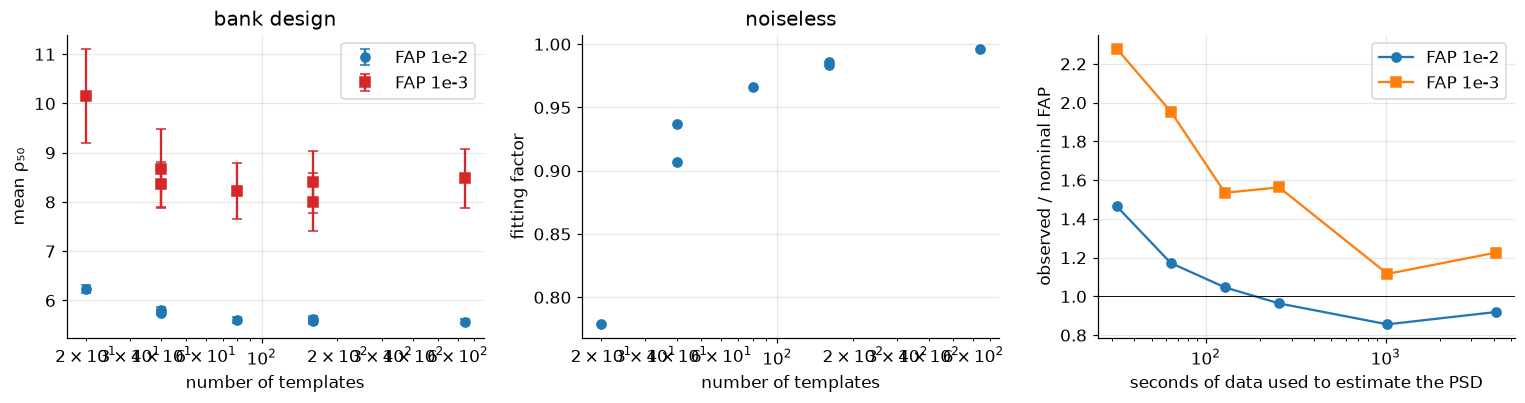

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].errorbar(BD.n_templates, BD.rho50_1e2, BD.err_1e2, fmt="o", color=g.COLORS["freq"], capsize=3, label="FAP 1e-2"); ax[0].errorbar(BD.n_templates, BD.rho50_1e3, BD.err_1e3, fmt="s", color=g.COLORS["bayes"], capsize=3, label="FAP 1e-3")
ax[0].set_xscale("log"); ax[0].set_xlabel("number of templates"); ax[0].set_ylabel("mean ρ₅₀"); ax[0].legend(); ax[0].set_title("bank design")
ax[1].plot(BD.n_templates, BD.fitting_factor, "o"); ax[1].set_xscale("log"); ax[1].set_xlabel("number of templates"); ax[1].set_ylabel("fitting factor"); ax[1].set_title("noiseless")
ax[2].semilogx(PU.index, PU.FAP_at_ideal_1e2 / 1e-2, "o-", label="FAP 1e-2"); ax[2].semilogx(PU.index, PU.FAP_at_ideal_1e3 / 1e-3, "s-", label="FAP 1e-3"); ax[2].axhline(1, color="k", lw=.6); ax[2].set_xlabel("seconds of data used to estimate the PSD"); ax[2].set_ylabel("observed / nominal FAP"); ax[2].legend()
fig.tight_layout(); g.savefig(fig, "fig27_bank_whitening_psd"); plt.show()
g.save_json(dict(bank_design=BD.reset_index().to_dict("records"), local_whitening_loo=LOO.to_dict("records"), local_whitening_rho50=EL.to_dict("records"), psd_uncertainty=PU.reset_index().to_dict("records")), "27_summary.json")

## Output and next step

`results/27_summary.json`, `figures/fig27_bank_whitening_psd`. Next: the Bayesian coherent and evidence analyses (extensions 36, 37, 35) and the physics extensions.